# Speculative positioning: CFTC Commitments of Traders

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UnbiasedAlpha/aurastream-python/blob/main/examples/03_cftc_positioning.ipynb)

Every Friday the CFTC publishes who is long and short in US futures. Extreme speculative positioning is a classic contrarian signal.

This notebook pulls **COT positioning for gold and the euro** and overlays it on price. It also uses AuraStream's **release-date stamping** (`as_of="release"`), so each row is dated when the market could actually see it, which keeps look-ahead bias out of your backtests.

**Sources:** `cftc`, `binance`, `sdmx` (ECB) · no provider accounts needed · **Calls used:** 4 of your 500 free monthly calls

In [1]:
%pip install -q "aurastream[pandas]" matplotlib

import os, getpass
if not os.environ.get("AURASTREAM_API_KEY"):
    # Free key, 500 calls/month, no card: https://aurastream.unbiased-alpha.com
    os.environ["AURASTREAM_API_KEY"] = getpass.getpass("AuraStream API key: ")

import pandas as pd
import matplotlib.pyplot as plt
from aurastream_client import AuraStream

client = AuraStream()

## 1. Pull COT reports

`GC` (gold) defaults to the **disaggregated** report, whose *managed money* group is the hedge funds and CTAs. For `6E` (euro FX) this notebook asks for the **legacy** report, whose *non-commercial* group is the classic speculator measure with the longest history. (Financial futures default to the Traders in Financial Futures report.)

In [2]:
START, END = "2018-01-01", "2025-10-31"

from aurastream_client.frames import to_frame
gold_cot = to_frame(client.timeseries("GC", START, END, "1w", source="cftc", as_of="release"), "GC")
euro_cot = to_frame(client.timeseries("6E", START, END, "1w", source="cftc", as_of="release", report="legacy"), "6E")
print("Gold columns:", list(gold_cot.columns)[:25])
print("Euro columns:", list(euro_cot.columns)[:25])

Gold columns: ['open_interest_all', 'prod_merc_positions_long', 'prod_merc_positions_short', 'swap_positions_long_all', 'swap__positions_short_all', 'swap__positions_spread_all', 'm_money_positions_long_all', 'm_money_positions_short_all', 'm_money_positions_spread', 'other_rept_positions_long', 'other_rept_positions_short', 'other_rept_positions_spread', 'tot_rept_positions_long_all', 'tot_rept_positions_short', 'nonrept_positions_long_all', 'nonrept_positions_short_all', 'open_interest_old', 'prod_merc_positions_long_1', 'prod_merc_positions_short_1', 'swap_positions_long_old', 'swap__positions_short_old', 'swap__positions_spread_old', 'm_money_positions_long_old', 'm_money_positions_short_old', 'm_money_positions_spread_1']
Euro columns: ['open_interest_all', 'noncomm_positions_long_all', 'noncomm_positions_short_all', 'noncomm_postions_spread_all', 'comm_positions_long_all', 'comm_positions_short_all', 'tot_rept_positions_long_all', 'tot_rept_positions_short', 'nonrept_positions_lo

Column names follow the CFTC report. The helper below finds the speculative long and short columns: *managed money* in the disaggregated report, *non-commercial* in the legacy one.

In [3]:
import re

def spec_net(df, group_patterns):
    """Net speculative position (long - short) for the first trader group found."""
    cols = {c.lower(): c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])}
    skip = ("spread", "change", "pct", "conc", "trader", "old", "other")
    def pick(pat, side):
        found = [cols[c] for c in cols if re.search(pat, c) and side in c and not any(k in c for k in skip)]
        return sorted(found, key=lambda c: "all" not in c.lower())  # prefer "..._all" columns
    for pat in group_patterns:
        longs, shorts = pick(pat, "long"), pick(pat, "short")
        if longs and shorts:
            print(f"Using {longs[0]!r} - {shorts[0]!r}")
            return df[longs[0]] - df[shorts[0]]
    raise KeyError("Speculative columns not found; inspect df.columns and pick them manually")

gold_net = spec_net(gold_cot, [r"m_?money|managed", r"noncomm"])
euro_net = spec_net(euro_cot, [r"noncomm"])

Using 'm_money_positions_long_all' - 'm_money_positions_short_all'
Using 'noncomm_positions_long_all' - 'noncomm_positions_short_all'


## 2. Positioning z-score vs. price

Prices: gold from Pax Gold (`PAXGUSDT` on Binance, a token backed by one ounce of London gold, from August 2020), the euro from the ECB's daily reference rate.

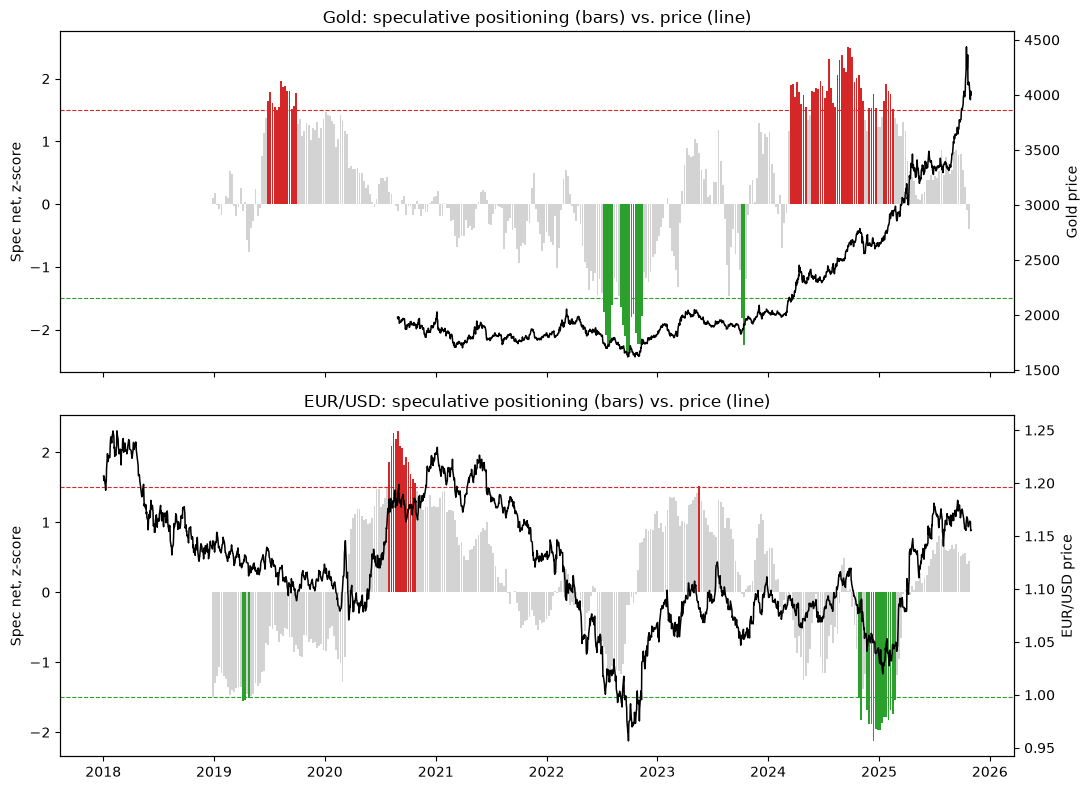

In [4]:
gold_px = client.get_frame("PAXGUSDT", START, END, "1d", source="binance")["Close"]
gold_px.index = gold_px.index.normalize() - pd.Timedelta(days=1)   # Binance daily bars are stamped at their close

eur = client.get_frame("ECB,EXR,1.0/D.USD.EUR.SP00.A", START, END, source="sdmx", db="ECB")["Value"]
eur = eur.loc[START:END]                                            # SDMX returns the full history

def zscore(s, window=156):  # 3 years of weekly reports
    return (s - s.rolling(window, min_periods=52).mean()) / s.rolling(window, min_periods=52).std()

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for ax, (name, net, price) in zip(axes, [("Gold", gold_net, gold_px), ("EUR/USD", euro_net, eur)]):
    z = zscore(net.sort_index())
    ax.bar(z.index, z, width=6, color=["tab:red" if v > 1.5 else "tab:green" if v < -1.5 else "lightgrey" for v in z])
    ax.axhline(1.5, ls="--", color="tab:red", lw=0.8); ax.axhline(-1.5, ls="--", color="tab:green", lw=0.8)
    ax.set_ylabel("Spec net, z-score")
    ax2 = ax.twinx(); ax2.plot(price.index, price, color="black", lw=1.1); ax2.set_ylabel(f"{name} price")
    ax.set_title(f"{name}: speculative positioning (bars) vs. price (line)")
plt.tight_layout()

## 3. Does extreme positioning predict returns?

Forward 8-week returns after crowded-long (z > 1.5) and crowded-short (z < -1.5) readings, compared with all weeks. Few weeks are extreme, so treat the averages as a first look, not a result.

In [5]:
def forward_test(net, price, weeks=8):
    z = zscore(net.sort_index())
    weekly = price.resample("W-FRI").last()
    fwd = weekly.shift(-weeks) / weekly - 1
    z_w = z.resample("W-FRI").last().reindex(weekly.index).ffill()
    groups = {"crowded long": z_w > 1.5, "neutral": z_w.abs() <= 1.5, "crowded short": z_w < -1.5, "all weeks": z_w.notna()}
    return pd.DataFrame({"avg fwd 8w return %": {k: fwd[m].mean() * 100 for k, m in groups.items()},
                         "weeks": {k: int(fwd[m].notna().sum()) for k, m in groups.items()}})

pd.concat({"Gold": forward_test(gold_net, gold_px), "EUR/USD": forward_test(euro_net, eur)}, axis=1).round(2)

Gold                   EUR/USD      
              avg fwd 8w return % weeks avg fwd 8w return % weeks
crowded long                 4.88    42                0.90    14
neutral                      1.74   203               -0.04   317
crowded short                3.18    18                1.65    19
all weeks                    2.34   263                0.09   350

## Takeaways

- Positioning extremes can serve as a **contrarian filter** rather than a timing tool; test them alongside trend or carry before relying on them.
- **Release-date stamping matters.** COT data is as of Tuesday but published Friday. A backtest that uses the report date looks ahead by three days.
- Want ready-made **short crowding** for US stocks (short interest, days to cover, fails-to-deliver)? See the `short_crowding` dataset in [Nemeton Signals](https://aurastream.unbiased-alpha.com/docs/data-sources/signals/).

---
### Next steps

- **Get a free key**: 500 calls a month, no card: [aurastream.unbiased-alpha.com](https://aurastream.unbiased-alpha.com)
- **Docs**: [aurastream.unbiased-alpha.com/docs](https://aurastream.unbiased-alpha.com/docs/)
- **Use it from Claude or ChatGPT**: `pip install aurastream-mcp`
- Found this useful? ⭐ the repo: [github.com/UnbiasedAlpha/aurastream-python](https://github.com/UnbiasedAlpha/aurastream-python)

*Built by [Unbiased Alpha](https://unbiased-alpha.com). For research and education only; not investment advice.*